# Predicting 30-Day Hospital Readmission for Diabetic Patients

**Question:** which diabetic patients are likely to be readmitted within 30 days of discharge?

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/diabetic_data.csv', na_values='?', low_memory=False)
print(df.shape)   # (rows, columns)

# The outcome: readmitted within 30 days ('<30'), after 30 days ('>30') or not at all ('NO').
# normalize=True shows each value's share instead of a count.
df['readmitted'].value_counts(normalize=True)

(101766, 50)


readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

## 2. Clean and define the target

In [2]:
# Patients who died or went to hospice cannot be readmitted (codes from IDS_mapping.csv).
# isin() checks for any of the codes; ~ means NOT, so those rows are removed.
df = df[~df['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]

# Keep each patient's first encounter, so one patient can't sit in both train and test
df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')
df = df[df['gender'] != 'Unknown/Invalid']   # drop the few rows with no usable gender

# The thing to predict: 1 if readmitted within 30 days, otherwise 0
df['target'] = (df['readmitted'] == '<30').astype(int)
print(len(df), round(df['target'].mean(), 3))   # about 70K patients, about 9% readmitted

69987 0.09


## 3. Feature engineering

In [3]:
df = df.drop(columns=['weight', 'payer_code'], errors='ignore')  # mostly missing

# Age comes in bands like '[70-80)'. Take the first number and add 5 to get the middle of the band.
df['age_num'] = df['age'].str.extract(r'\[(\d+)')[0].astype(int) + 5   # '[70-80)' -> 75
# All visits in the year before this stay: a strong sign of how unwell the patient is
df['prior_visits'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']

# Each diabetes drug column holds 'No', 'Steady', 'Up' or 'Down'.
# .loc[:, 'metformin':'metformin-pioglitazone'] selects every column from metformin to the last drug.
med_cols = df.loc[:, 'metformin':'metformin-pioglitazone'].columns   # the 23 diabetes drugs
df['n_meds_used'] = (df[med_cols] != 'No').sum(axis=1)                 # drugs the patient was on
df['n_meds_changed'] = df[med_cols].isin(['Up', 'Down']).sum(axis=1)   # doses changed in hospital

def icd9_group(code):
    """Turn one ICD-9 diagnosis code into one of 9 broad clinical groups."""
    if pd.isna(code):
        return 'Missing'
    code = str(code)
    if code[0] in 'VE':   # V and E codes are supplementary (check-ups, external causes)
        return 'Other'
    n = int(float(code))  # '250.83' -> 250: the part before the dot is the disease family
    if 390 <= n <= 459 or n == 785: return 'Circulatory'
    if 460 <= n <= 519 or n == 786: return 'Respiratory'
    if 520 <= n <= 579 or n == 787: return 'Digestive'
    if n == 250: return 'Diabetes'
    if 800 <= n <= 999: return 'Injury'
    if 710 <= n <= 739: return 'Musculoskeletal'
    if 580 <= n <= 629 or n == 788: return 'Genitourinary'
    if 140 <= n <= 239: return 'Neoplasms'
    return 'Other'

# Group the primary diagnosis (diag_1) and the two secondary ones
for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col + '_grp'] = df[col].map(icd9_group)

# The columns the model will use. Numeric columns are amounts; categorical columns are labels.
# The *_id columns hold numbers, but they are codes, not amounts, so they count as labels.
numeric = ['age_num', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
           'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses',
           'prior_visits', 'n_meds_used', 'n_meds_changed']
categorical = ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
               'medical_specialty', 'max_glu_serum', 'A1Cresult', 'insulin', 'metformin',
               'change', 'diabetesMed', 'diag_1_grp', 'diag_2_grp', 'diag_3_grp']
# Missing labels become their own label, 'Missing'; astype(str) makes every label text
df[categorical] = df[categorical].fillna('Missing').astype(str)

## 4. Explore

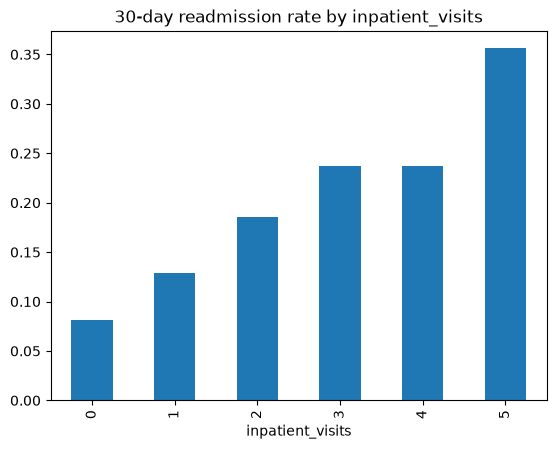

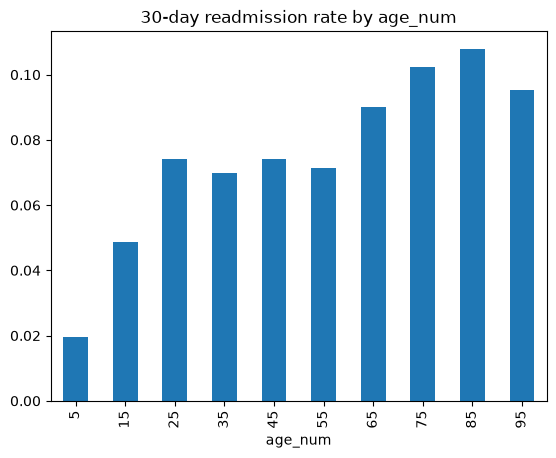

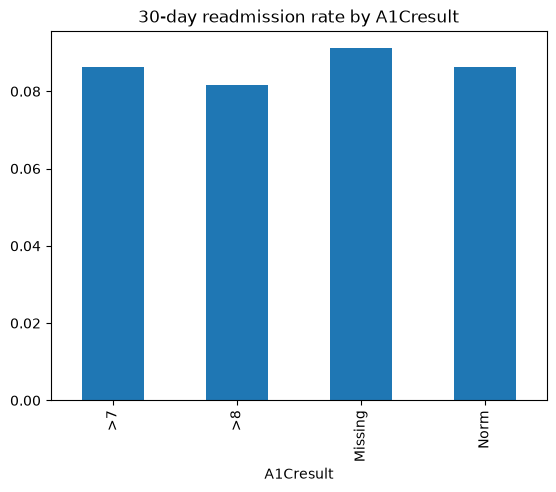

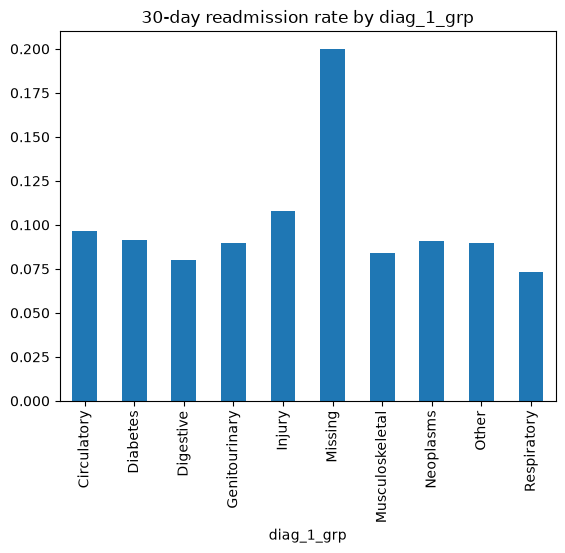

In [4]:
# Cap prior inpatient visits at 5, so the rare patients with 10+ visits don't add many tiny bars
df['inpatient_visits'] = df['number_inpatient'].clip(upper=5)   # 5 means 5 or more
# For each column: the readmission rate in each group (the mean of a 0/1 column is a rate)
for col in ['inpatient_visits', 'age_num', 'A1Cresult', 'diag_1_grp']:
    df.groupby(col)['target'].mean().plot(kind='bar', title=f'30-day readmission rate by {col}')
    plt.show()

**What I found:** _one sentence per chart: which groups have the highest readmission rate?_

## 5. Split and preprocess

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

X, y = df[numeric + categorical], df['target']   # X = the inputs, y = what to predict
# Keep 20% of patients aside as the final test. stratify=y keeps the 9% readmission rate in both
# parts; random_state=42 makes the split the same every time you run it.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Preprocessing that runs inside every model, so the test data never influences the fitting:
# - numeric columns are rescaled to mean 0 and standard deviation 1 (Logistic Regression needs this)
# - each label becomes its own 0/1 column (one-hot encoding). Labels seen fewer than 100 times
#   are pooled into one 'infrequent' column, and labels never seen in training don't cause errors.
pre = ColumnTransformer([
    ('num', StandardScaler(), numeric),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100,
                          sparse_output=False), categorical),
])

## 6. Compare models with cross-validation

Published models on this dataset score about 0.62–0.70 ROC-AUC. Models within about 0.01 of each other are tied.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()   # weight for the rare class
models = {
    # Always predicts the average rate: the floor every real model must beat (ROC-AUC 0.5)
    'Baseline': DummyClassifier(strategy='prior'),
    # class_weight='balanced' makes mistakes on the rare readmitted patients count more
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    # 300 decision trees; min_samples_leaf=20 stops the trees from memorising single patients
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            class_weight='balanced_subsample', random_state=42),
    # Gradient boosting: 400 small trees (depth 4), each one correcting the trees before it.
    # subsample and colsample_bytree give each tree 80% of the rows and columns, which reduces
    # overfitting; scale_pos_weight plays the same role as class_weight above.
    'XGBoost': XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='auc',
                             random_state=42),
}

# 5-fold cross-validation: split the training data into 5 parts, train on 4 and score on the 5th,
# five times over. The mean is a fair estimate of the score; the ± spread shows how stable it is.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    # The pipeline keeps preprocessing and model together; n_jobs=-1 uses all CPU cores
    scores = cross_val_score(Pipeline([('pre', pre), ('model', model)]),
                             X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f'{name}: ROC-AUC {scores.mean():.3f} ± {scores.std():.3f}')

Baseline: ROC-AUC 0.500 ± 0.000
Logistic Regression: ROC-AUC 0.646 ± 0.004
Random Forest: ROC-AUC 0.655 ± 0.007
XGBoost: ROC-AUC 0.652 ± 0.005


## 7. Tuning the best model

In [7]:
winner = 'XGBoost'   

# The settings worth trying for each model:
# - Logistic Regression: C sets how simple the model is forced to be (small C = simpler)
# - Random Forest: bigger leaves and fewer columns per split make the trees more general
param_grids = {
    'XGBoost': {'model__max_depth': [3, 4, 6],
                'model__learning_rate': [0.03, 0.1],
                'model__n_estimators': [300, 600]},
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'Random Forest': {'model__min_samples_leaf': [5, 20, 50],
                      'model__max_features': ['sqrt', 0.3]},
}
grid = GridSearchCV(Pipeline([('pre', pre), ('model', models[winner])]),
                    param_grids[winner], cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_, round(grid.best_score_, 3))
best = grid.best_estimator_

{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 300} 0.656


## 8. Test once on held-out data

ROC-AUC: 0.656
PR-AUC : 0.188 | random guess would be 0.09
Share of readmissions caught by flagging the riskiest 20%: 0.387


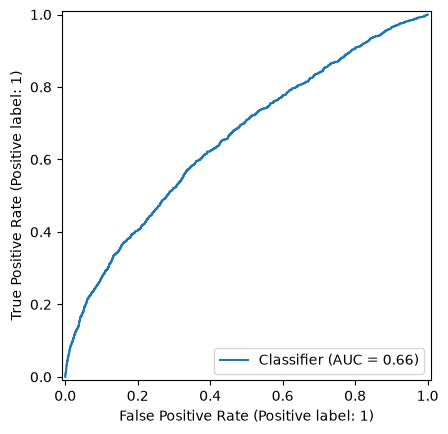

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay

# Predicted probability of readmission for every test patient (column 1 = the "readmitted" class)
proba = best.predict_proba(X_test)[:, 1]
# ROC-AUC: the chance that a random readmitted patient gets a higher risk score than a random
# patient who wasn't readmitted (0.5 = guessing, 1.0 = perfect)
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3))
# PR-AUC: how precise the model is at each level of recall for the rare class;
# guessing scores about the readmission rate
print('PR-AUC :', round(average_precision_score(y_test, proba), 3),
      '| random guess would be', round(y_test.mean(), 3))

# Flag the 20% of patients with the highest predicted risk (above the 80th percentile)
# and check what share of all readmissions they include
top20 = proba >= np.quantile(proba, 0.8)
print('Share of readmissions caught by flagging the riskiest 20%:',
      round(y_test[top20].sum() / y_test.sum(), 3))

RocCurveDisplay.from_predictions(y_test, proba)   # draws the ROC curve
plt.savefig('images/roc_curve.png', dpi=150)

**What I found:** The tuned XGBoost model achieved a ROC-AUC of 0.661 on the held-out test set, indicating modest ability to distinguish patients who were readmitted within 30 days from those who were not. Its performance was consistent with the cross-validation score of 0.656.

## 9. Explain the model

Run the SHAP cell only if the winner is XGBoost (it is very slow for Random Forest and does not work for Logistic Regression). Permutation importance works for any model.

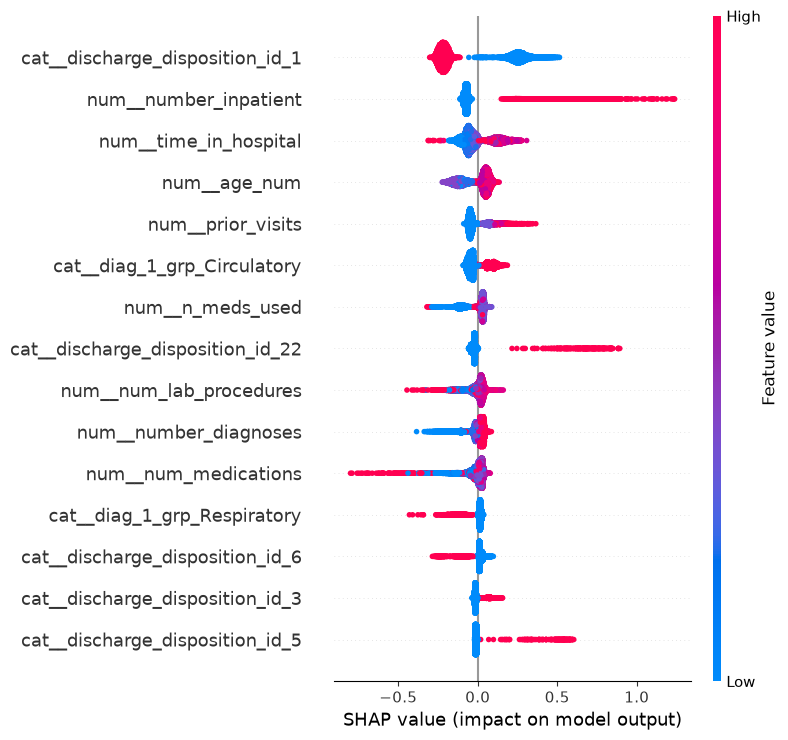

In [9]:
import shap

# SHAP explains the model's own inputs, so first run the test data through the preprocessing step
X_test_t = best.named_steps['pre'].transform(X_test)
names = best.named_steps['pre'].get_feature_names_out()   # e.g. 'num__number_inpatient'
explainer = shap.TreeExplainer(best.named_steps['model'])   # fast, exact explainer for tree models
shap_values = explainer.shap_values(X_test_t)   # per patient and feature: how much it moved the risk

# One row per feature, most important at the top; one dot per patient.
# Dots right of 0 raise the predicted risk and dots left of 0 lower it;
# red means a high value of that feature, blue a low one.
shap.summary_plot(shap_values, X_test_t, feature_names=names, max_display=15, show=False)
plt.savefig('images/shap_summary.png', dpi=150, bbox_inches='tight')

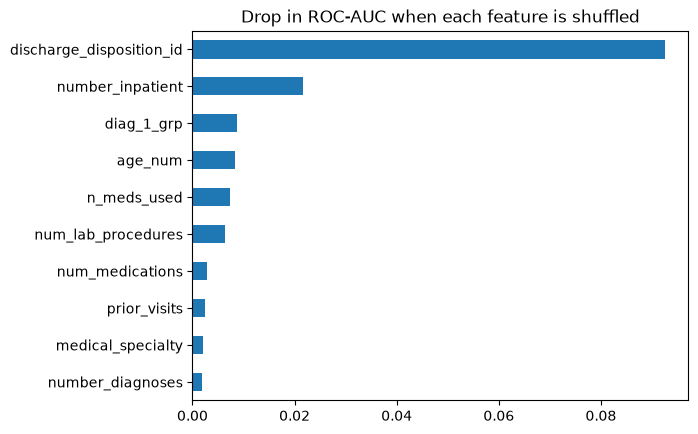

In [10]:
from sklearn.inspection import permutation_importance

# Shuffle one column at a time and see how much ROC-AUC drops: works for any model.
# A 3,000-patient sample keeps it fast; y_test.loc[sample.index] picks the same patients' outcomes.
sample = X_test.sample(3000, random_state=42)
result = permutation_importance(best, sample, y_test.loc[sample.index], scoring='roc_auc',
                                n_repeats=5, random_state=42, n_jobs=-1)   # 5 shuffles per column
importance = pd.Series(result.importances_mean, index=sample.columns).sort_values()   # average drop
importance.tail(10).plot(kind='barh', title='Drop in ROC-AUC when each feature is shuffled')   # top 10
plt.savefig('images/risk_drivers.png', dpi=150, bbox_inches='tight')

**What I found:** Discharge disposition was the strongest predictor of readmission, followed by previous inpatient visits and primary diagnosis group. These findings highlight the importance of discharge planning and patients' prior healthcare utilization